<font color ='Navy'><center> __BruFace__ </center></font>
<br> MA1 Mechanical Engineering <br>  __Mechanical vibrations__ <br>
**Academic Year 2026-2027**
***
<font color='Navy'><h1><center>Project: 4 DOFs Model of a Car Under Road Excitation </center></h1></font>
- Arnaud Deraemaeker ([Arnaud.Deraemaeker@ulb.be](mailto:Arnaud.Deraemaeker@ulb.be))  
- Wout Weijtjens ([Wout.Weijtjens@vub.be](mailto:Wout.Weijtjens@vub.be))
***


# **1. Model and equations**

Consider the 4 DOFs model of a car represented below. $X_{01}$ and $X_{02}$ represent the motion imposed on each wheel due to the road profile. The car body is assumed to be rigid and the motion is restricted to a plane, resulting in 2 DOFs (translation, rotation), while each wheel is also assumed to be a rigid body and can only move vertically. $K_0, B_0$ are the mechanical parameters of the car suspension, while $k, b$ are the stiffness and damping of the tires.

---

## **Model Diagram**
![4 DOFs Model of a Car](https://github.com/OWI-Lab/MV2627_Exercises/blob/main/Project2627/images/car.png?raw=1)

---

1. Based on the equations of motion derived for each body separately, derive the full set of equations of motion for the car in a matrix form, and determine the mass, damping, and stiffness matrices. Use absolute displacements in the equations. Give the expression of the force vector.

2. Assume harmonic excitation and write the equations of motion in the frequency domain.
What assumption could you make to have the force vector independent of the frequency?
Give the expression of the force vector in this simplified case.

***Small Angle Assumption*** : It is assumed that the rotation angles of the car body are small enough such that $sin⁡(q3)≈q3$. This linearizes the rotational dynamics, allowing for the use of linear equations of motion.


In [1]:
import sys
import os

# Only if the session is opend in google colab link
if "google.colab" in sys.modules:
    repo = "/content/MV2627_Exercises"
    if not os.path.exists(repo):
        !git clone -q https://github.com/OWI-Lab/MV2627_Exercises.git {repo}
    %cd /content/MV2627_Exercises/Project2627
    !pip install -q uv

/content/MV2627_Exercises/Project2627


# **2. Frequency Domain Computations**

Consider the following values of the parameters:
- $M_0 = 1500 \, \text{kg}$
- $K_0 = 65 000 \, \text{N/m}$
- $B_0 = 65 \, \text{N/(m/s)}$
- $m = 10 \, \text{kg}$
- $k = 100 000 \, \text{N/m}$
- $b = 10 \, \text{N/(m/s)}$
- $L = 4 \, \text{m}$
- $I_G = 5700 \, \text{kg} \cdot \text{m}^2$

Answer the following questions providing your answer to each question in the cell below it and in a separate code cell.

## **2.1 Computation of transmissibilities**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Compute the mode shapes and the natural frequencies of the car. Give a physical interpretation of each of the mode shapes (what kind of motion of the car is related to each mode shape)

</div>

In [3]:
import numpy as np
import scipy.linalg as sl
M0=1500
K0=65000
B0=65
m=10
k=100000
b=10
L=4
IG=5700
M = np.diag([m, m, M0, IG])
C = np.array([
        [B0 + b, 0,      -B0,    L/2 * B0],
        [0,      B0 + b, -B0,   -L/2 * B0],
        [-B0,   -B0,      2*B0,  0],
        [L/2 * B0, -L/2 * B0, 0,     L**2/2 * B0]
    ])


K = np.array([
        [K0 + k, 0,      -K0,    L/2 * K0],
        [0,      K0 + k, -K0,   -L/2 * K0],
        [-K0,   -K0,      2*K0,  0],
        [L/2 * K0, -L/2 * K0, 0,     L**2 / 2 * K0]
    ])
lam, V = sl.eigh(K, M)
w = np.sqrt(lam)
f = w/(2*np.pi)
V = V / np.abs(V).max(axis=0)
print(f); print(V)


[ 1.15226913  1.18213852 20.46502995 20.46614925]
[[ 3.95194831e-01  7.90521966e-01 -1.00000000e+00 -1.00000000e+00]
 [ 3.95194831e-01 -7.90521966e-01 -1.00000000e+00  1.00000000e+00]
 [ 1.00000000e+00  2.41358635e-13  5.26926441e-03  8.14946211e-16]
 [ 6.36259589e-14 -1.00000000e+00  4.34493666e-16 -2.77376129e-03]]


In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Assuming $X_{01} = X_{02}$ , compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when X01 = X02? Can you make a link with the peaks present in the transmissibility curve?

</div>

peak at 1.153 Hz, |X3/X01| = 213.318, |q3/X01| = 0.00e+00
peak at 20.412 Hz, |X3/X01| = 0.055, |q3/X01| = 4.20e-18


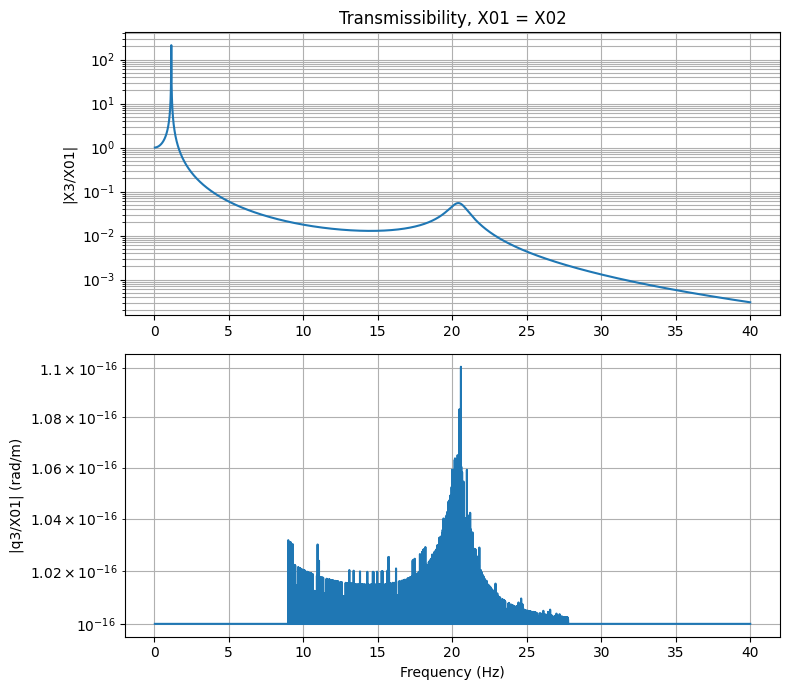

In [5]:

import matplotlib.pyplot as plt



f = np.linspace(0.05, 40, 40000)
T = np.zeros(len(f), complex); R = np.zeros(len(f), complex)
for i, fi in enumerate(f):
    w = 2*np.pi*fi
    F = (k + 1j*w*b) * np.array([1, 1, 0, 0])     # X01 = X02 = 1, full force vector
    q = np.linalg.solve(-w**2*M + 1j*w*C + K, F)
    T[i], R[i] = q[2], q[3]

A = np.abs(T)
pk = [i for i in range(1,len(f)-1) if A[i]>A[i-1] and A[i]>A[i+1]]
for i in pk: print(f"peak at {f[i]:.3f} Hz, |X3/X01| = {A[i]:.3f}, |q3/X01| = {abs(R[i]):.2e}")

fig, ax = plt.subplots(2,1,figsize=(8,7))
ax[0].semilogy(f, A); ax[0].set_ylabel("|X3/X01|"); ax[0].grid(True, which="both")
ax[0].set_title("Transmissibility, X01 = X02")
ax[1].semilogy(f, np.abs(R)+1e-16); ax[1].set_ylabel("|q3/X01| (rad/m)")
ax[1].set_xlabel("Frequency (Hz)"); ax[1].grid(True, which="both")
plt.tight_layout();

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Now, use the simplified force vector derived in point 1.2, compute and represent the transmissibility $X_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Assuming $X_{01} = −X_{02}$ , compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations (no simplification of the force vector). Identify to which mode shapes and resonance frequencies the peaks in the transmissibility curve belong. Which kind of imposed motion is applied when $X_{01} = −X_{02}$ ? Can you make a link with the peaks present in the transmissibility curve?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Use the simplified force vector derived in point 1.2, compute and represent the transmissibility $q_{3}/X_{01}$ using the full model with the coupled equations. Compare with the previous case by plotting the two curves on the same graph and comment. Is the simplification used for the force vector valid in your opinion?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

6. The transmissibilities are used in the theory of vibration isolation. Comment on the shape of these and make a link with the theory in the course. In your opinion, which frequency bands correspond to the amplification and the isolation domain? What role do the wheels play in the isolation?

</div>


### Add your explanation here

## **2.2 Projection in the modal basis**


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Using the simplified force vector, project the equations of motion in the modal domain. Are the equations uncoupled? Why?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. If they are coupled, propose a simplification to decouple the equations of motion, and check its validity by comparing the transmissibility curves $X_{3}/X_{01}$ (assume $X_{01} = X_{02}$ as above), and $q_{3}/X_{01}$ (assume $X_{01} = −X_{02}$ as above) obtained with the full model, and with the decoupled modal projection approach. Is your assumption valid?

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

# **3. Time Domain Computations**

Assume now a given road profile $w$ and $X_{01} \neq X_{02}$. Using the equations with ***absolute coordinates***, and using the simplified force vector used above:


<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

1. Knowing that the frequency of excitation depends on the velocity of the car $v$ and the road profile (in particular the amplitude of its different wavelengths) and using a Fourier transform of the road profile, plot the frequency content of the excitation for three different speeds of the car ($v=5 m/s$, $v= 10 m/s$ and $v=30m/s$).

*N.B.: The road profile is defined in the **w.csv** file (first column: spatial coordinate, second column: road profile amplitude)*

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

2. Compute and represent the absolute displacement $X_{3}(t)$ for the three car speeds. Use a convolution between the force vector and the impulse responses, and work with the uncoupled equations in the modal basis. (hint: consider $X_{01}$ and $X_{02}$ as two independent excitation sources, and sum the responses using the property of linearity of the system). Use a relative time ($t/tmax$) in order to plot the curves on the same graph and compare.

*Hint: Use the function `convolve` from `scipy.signal` to compute the convolution as it is faster that numpy*

*Hint: When convolving the force vector with the impulse response, make sure to multiply the result by the time step to get the correct result*
</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

3. Represent the frequency content of the three time domain signals obtained. Compare it to the frequency content of the excitation and comment. What differences do you see for the three different velocities and why ?

</div>

In [ ]:
### Add your code here

In [ ]:
### Add your code here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

4. Do you notice a difference in the time domain responses in terms of amplitude? Why? Can you make a link with the transmissibility curves computed previously? Can you make a link with the theory covered in the chapter about vibration isolation? At which speed(s) is the car body best isolated?

</div>


### Add your explanation here

<div style="border-left: 1px solid black; padding: 1em; margin: 1em 0;">

5. Repeat points (2) to (4) for $q_{3}(t)$ at the three different speeds.

</div>


In [ ]:
### Add your code here

In [ ]:
### Add your code here